# Gradient Boosting Step by Step:

Gradient boosting for regression, built by hand. Start from the mean, then repeatedly fit a small tree to the residuals and add it to the prediction, scaled by a learning rate.

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor

from sklearn.tree import plot_tree

## Data:

100 points from a noisy parabola, y = 3x² + noise. A straight line can't fit this, but a sum of small trees can.

In [2]:
np.random.seed(42)
X = np.random.rand(100, 1) - 0.5
y = 3*X[:, 0]**2 + 0.05 * np.random.randn(100)

In [3]:
df = pd.DataFrame()

In [4]:
df['X'] = X.reshape(100)
df['y'] = y

df

,X,y
0,-0.125460,0.051573
1,0.450714,0.594480
2,0.231994,0.166052
3,0.098658,-0.070178
4,-0.343981,0.343986
...,...,...
95,-0.006204,-0.040675
96,0.022733,-0.002305
97,-0.072459,0.032809
98,-0.474581,0.689516


Text(0.5, 1.0, 'X vs Y')

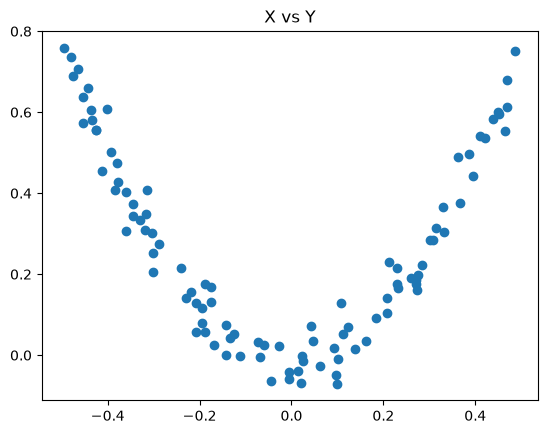

In [5]:
plt.scatter(df['X'],df['y'])
plt.title('X vs Y')

## Round 0: start with the mean:

The first prediction is the mean of `y` for every point. The residual, `y - prediction`, is what is left to explain. For squared error it is exactly the negative gradient of the loss, which is where the name comes from.

In [6]:
f0 = df['y'].mean()
lr = 0.5

df['pred1'] = f0
df

,X,y,pred1
0,-0.125460,0.051573,0.265458
1,0.450714,0.594480,0.265458
2,0.231994,0.166052,0.265458
3,0.098658,-0.070178,0.265458
4,-0.343981,0.343986,0.265458
...,...,...,...
95,-0.006204,-0.040675,0.265458
96,0.022733,-0.002305,0.265458
97,-0.072459,0.032809,0.265458
98,-0.474581,0.689516,0.265458


In [7]:
df['res1'] = df['y'] - df['pred1']
df

,X,y,pred1,res1
0,-0.125460,0.051573,0.265458,-0.213885
1,0.450714,0.594480,0.265458,0.329021
2,0.231994,0.166052,0.265458,-0.099407
3,0.098658,-0.070178,0.265458,-0.335636
4,-0.343981,0.343986,0.265458,0.078528
...,...,...,...,...
95,-0.006204,-0.040675,0.265458,-0.306133
96,0.022733,-0.002305,0.265458,-0.267763
97,-0.072459,0.032809,0.265458,-0.232650
98,-0.474581,0.689516,0.265458,0.424057


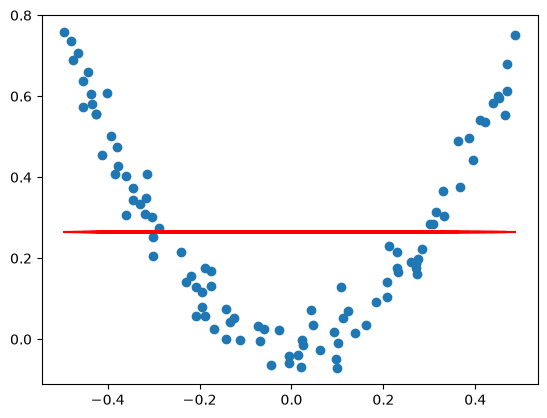

In [8]:
plt.scatter(df['X'],df['y'])
plt.plot(df['X'],df['pred1'],color='red')

## Round 1: fit a tree to the residuals:

An 8-leaf tree is trained to predict the residuals, and its output is added to the prediction **scaled by the learning rate**: `prediction = mean + lr * tree1`.
A smaller `lr` means smaller steps. It is 0.5 here so two rounds make visible progress.

In [9]:
tree1 = DecisionTreeRegressor(max_leaf_nodes=8)
tree1.fit(df['X'].values.reshape(100,1),df['res1'].values)

,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",8
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several split

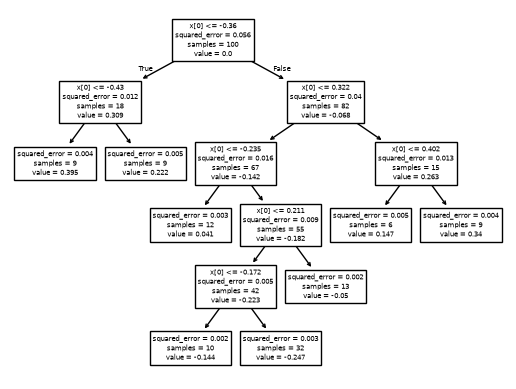

In [10]:
plot_tree(tree1)
plt.show()

In [11]:
X_test = np.linspace(-0.5, 0.5, 500)

In [12]:
y_pred = f0 + lr * tree1.predict(X_test.reshape(500, 1))

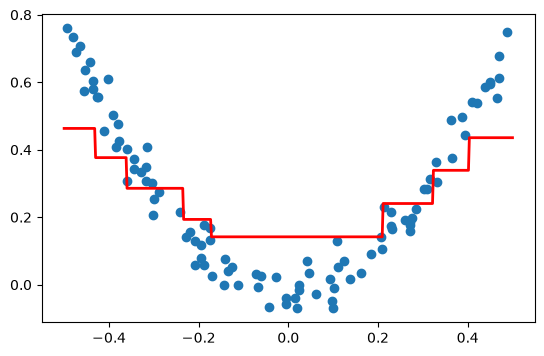

In [13]:
plt.figure(figsize=(14,4))
plt.subplot(121)
plt.plot(X_test, y_pred, linewidth=2,color='red')
plt.scatter(df['X'],df['y'])

In [14]:
df['pred2'] = f0 + lr * tree1.predict(df['X'].values.reshape(100, 1))
df

,X,y,pred1,res1,pred2
0,-0.125460,0.051573,0.265458,-0.213885,0.141889
1,0.450714,0.594480,0.265458,0.329021,0.435671
2,0.231994,0.166052,0.265458,-0.099407,0.240621
3,0.098658,-0.070178,0.265458,-0.335636,0.141889
4,-0.343981,0.343986,0.265458,0.078528,0.285712
...,...,...,...,...,...
95,-0.006204,-0.040675,0.265458,-0.306133,0.141889
96,0.022733,-0.002305,0.265458,-0.267763,0.141889
97,-0.072459,0.032809,0.265458,-0.232650,0.141889
98,-0.474581,0.689516,0.265458,0.424057,0.463185


In [15]:
df['res2'] = df['y'] - df['pred2']
df

,X,y,pred1,res1,pred2,res2
0,-0.125460,0.051573,0.265458,-0.213885,0.141889,-0.090316
1,0.450714,0.594480,0.265458,0.329021,0.435671,0.158809
2,0.231994,0.166052,0.265458,-0.099407,0.240621,-0.074570
3,0.098658,-0.070178,0.265458,-0.335636,0.141889,-0.212067
4,-0.343981,0.343986,0.265458,0.078528,0.285712,0.058274
...,...,...,...,...,...,...
95,-0.006204,-0.040675,0.265458,-0.306133,0.141889,-0.182564
96,0.022733,-0.002305,0.265458,-0.267763,0.141889,-0.144194
97,-0.072459,0.032809,0.265458,-0.232650,0.141889,-0.109080
98,-0.474581,0.689516,0.265458,0.424057,0.463185,0.226330


## Round 2: repeat on the new residuals:

The residuals are recomputed from the updated prediction, a second tree is fitted to them, and the prediction becomes `mean + lr * (tree1 + tree2)`.

In [16]:
tree2 = DecisionTreeRegressor(max_leaf_nodes=8)
tree2.fit(df['X'].values.reshape(100,1),df['res2'].values)

,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",8
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several split

In [17]:
y_pred = f0 + lr * sum(regressor.predict(X_test.reshape(-1, 1)) for regressor in [tree1, tree2])

Text(0.5, 1.0, 'X vs y')

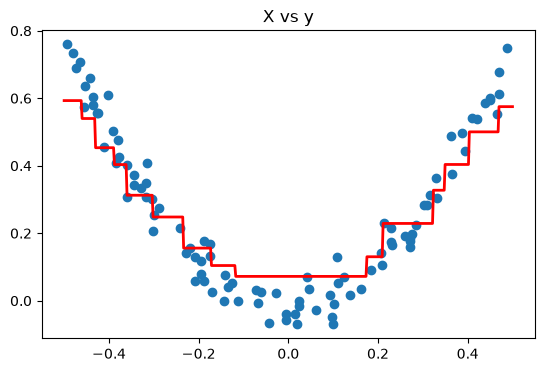

In [18]:
plt.figure(figsize=(14,4))
plt.subplot(121)
plt.plot(X_test, y_pred, linewidth=2,color='red')
plt.scatter(df['X'],df['y'])
plt.title('X vs y')

## The loop as a function:

Each round does the same three things: compute the residuals, fit a tree to them, and add `lr * tree`. With a small learning rate the curve improves gradually, so more trees are needed.

In [19]:
def gradient_boost(X, y, n_estimators, lr, max_depth=5, plot_every=1):
    f0 = y.mean()
    pred = np.full(len(y), f0)
    trees = []
    x_grid = np.linspace(-0.5, 0.5, 500).reshape(-1, 1)

    for m in range(1, n_estimators + 1):
        residual = y - pred
        tree = DecisionTreeRegressor(max_depth=max_depth, random_state=42)
        tree.fit(X, residual)
        trees.append(tree)

        pred = pred + lr * tree.predict(X)

        if m == 1 or m % plot_every == 0:
            y_grid = f0 + lr * sum(t.predict(x_grid) for t in trees)
            plt.figure()
            plt.plot(x_grid, y_grid, linewidth=2)
            plt.plot(X[:, 0], y, "r.")
            plt.title(f"After {m} tree(s), learning rate = {lr}")
            plt.show()

    return f0, trees

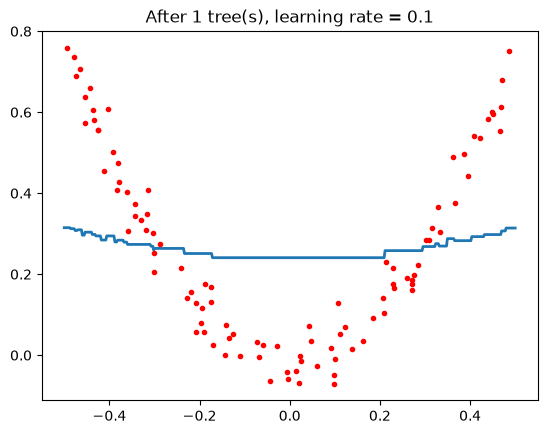

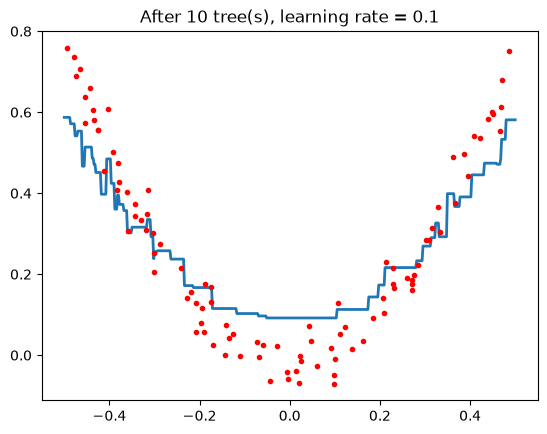

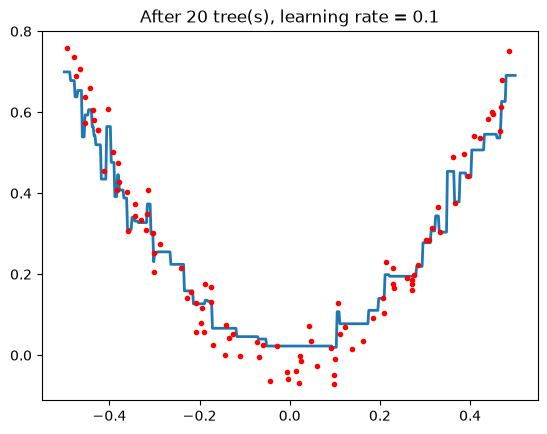

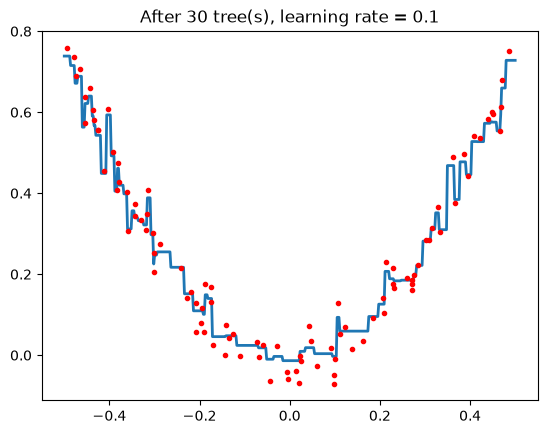

In [20]:
np.random.seed(42)
X = np.random.rand(100, 1) - 0.5
y = 3*X[:, 0]**2 + 0.05 * np.random.randn(100)

f0, trees = gradient_boost(X, y, n_estimators=30, lr=0.1, plot_every=10)

## Check against scikit-learn:

`GradientBoostingRegressor` with the same settings gives the same predictions, so the by-hand version is the real algorithm.

In [21]:
mine = f0 + 0.1 * sum(tree.predict(X) for tree in trees)
sk = GradientBoostingRegressor(n_estimators=30, learning_rate=0.1, max_depth=5, random_state=42).fit(X, y)

print("Same predictions as scikit-learn:", np.allclose(mine, sk.predict(X)))

Same predictions as scikit-learn: True
